In [22]:
# %%
# Insitu rainfall — Daily ordinary kriging
#
# Workflow per day:
#   1. Check wet-station threshold (derived from variogram geometry).
#      Below threshold → bilinear griddata + Gaussian smoothing fallback.
#   2. NSCORE transform on wet-station values only.
#   3. Compute omnidirectional experimental variogram from wet stations.
#   4. Fit nugget + partial_sill via WLS with range fixed at the
#      seasonally-calibrated value (derived in Section 6).
#      If per-day fit is under-determined → use full seasonal fallback params.
#   5. PyKrige ordinary kriging on UTM grid.
#   6. Back-transform via NSCORE lookup, clip negatives to zero.
#   7. Reproject to WGS84 and save one GeoTIFF per day.
#
# Seasonal fallback variogram params (Section 6):
#   For each season, wet-day station means from the calibration period are
#   used to fit a full 3-parameter variogram (nugget, partial_sill, range)
#   via iterative WLS.  The fitted range becomes the fixed range for all
#   per-day fits in that season, giving physically meaningful seasonal
#   variation in correlation length rather than a universal constant.
#   FIXED_RANGE_FALLBACK_KM is used only if seasonal calibration fails.
#
# Wet-station threshold derivation (Section 5):
#   For a valid experimental variogram with N_LAG bins, each needing
#   MIN_PAIRS pairs (Webster & Oliver 2007), total pairs required =
#   N_LAG × MIN_PAIRS.  With N stations, pairs = N(N-1)/2.  Solving for
#   the minimum N, then applying a 1.5× safety factor for uneven pair
#   distribution in irregular networks.

In [23]:
import math
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyproj import Proj
from scipy.optimize import curve_fit
from scipy.spatial.distance import pdist
from scipy.ndimage import gaussian_filter
from scipy.interpolate import griddata

import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject

import geostatspy.geostats as geostats
from pykrige.ok import OrdinaryKriging


# %%
# ── Section 1: User Configuration ─────────────────────────────────────────────

INSITU_CSV     = r"..\Data\Processed\Insitu\insitu_rainfall_1991_2020.csv"
TRAIN_STATIONS = r"..\Data\Processed\Split_stations\train_stations.csv"
TEST_STATIONS  = r"..\Data\Processed\Split_stations\test_stations.csv"

# WGS84 template — sole reference for output grid extent, resolution,
# and pixel registration.
TEMPLATE_WGS84 = r"..\Data\Datasets\CHIRPS_prec\CHIRPS_prec_19910101.tif"

# ── Calibration period for seasonal fallback variogram fitting ────────────────
CALIB_START_YEAR = 2001
CALIB_END_YEAR   = 2005

# ── Processing period ─────────────────────────────────────────────────────────
KRIG_START_DAY = pd.Timestamp('2001-01-01')
KRIG_END_DAY   = pd.Timestamp('2005-12-31')

# ── Variogram range ───────────────────────────────────────────────────────────
# The range used for per-day fitting is derived per season from the fallback
# calibration (Section 6) rather than set to a universal constant.
# FIXED_RANGE_FALLBACK_KM is used only when seasonal calibration fails entirely.
FIXED_RANGE_FALLBACK_KM = 100.0

# Sill fraction at which range is initialised for the iterative WLS fit
SILL_TARGET = 0.8

# ── Station / data thresholds ─────────────────────────────────────────────────
WET_STATION_THRESHOLD = 0.1   # mm — minimum to count as a wet station / wet day
MIN_WET_DAYS_FALLBACK = 5     # wet days a station must have (calibration period)
                               # to be included in seasonal fallback calibration

# ── Bilinear fallback smoothing ───────────────────────────────────────────────
# Gaussian sigma in pixels at 5 km resolution → 50 km effective smoothing.
GAUSSIAN_SMOOTH_SIGMA = 10

# ── Output ────────────────────────────────────────────────────────────────────
OUTPUT_DIR = r"..\Data\Processed\Bias_correction_daily\Insitu_kriged_daily"
TEMP_DIR   = r"..\Data\Processed\Bias_correction_daily\Insitu_kriged_daily\Temp"
VAR_DIR    = r"..\Data\Processed\Bias_correction_daily\Insitu_kriged_daily\Variogram_analysis"
NODATA_OUT = -9999.0

In [24]:
# %%
# ── Section 2: Fixed Constants ────────────────────────────────────────────────

UTM_PROJ = "+proj=utm +zone=45 +ellps=WGS84 +datum=WGS84 +units=m +no_defs"

SEASONS = {
    'winter':       [12, 1, 2],
    'pre_monsoon':  [3, 4, 5],
    'monsoon':      [6, 7, 8, 9],
    'post_monsoon': [10, 11],
}

COLORS = {
    'spherical':   'steelblue',
    'exponential': 'darkorange',
    'gaussian':    'forestgreen',
}

TMIN, TMAX = -9999, 9999
BANDWH     = 9999

# Model trial order for per-day fitting.
# Exponential is tried first — literature (Ly et al. 2011) shows it and
# Gaussian fit daily rainfall better than spherical.
MODEL_TRIAL_ORDER = ['exponential', 'gaussian', 'spherical']

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(TEMP_DIR,   exist_ok=True)
os.makedirs(VAR_DIR,    exist_ok=True)

FALLBACK_PARAMS_CSV = os.path.join(VAR_DIR, "fallback_variogram_params_daily.csv")
LOG_CSV             = os.path.join(OUTPUT_DIR, "daily_kriging_log.csv")

for p in [FALLBACK_PARAMS_CSV, LOG_CSV]:
    if os.path.exists(p):
        os.remove(p)

In [25]:
# %%
# ── Section 3: Helper Functions ───────────────────────────────────────────────

proj_utm = Proj(UTM_PROJ)


def get_season(month):
    for s, months in SEASONS.items():
        if month in months:
            return s
    return None


def coords_to_utm_km(lons, lats):
    """Project WGS84 lon/lat to UTM km.  Returns (x_km, y_km)."""
    x_m, y_m = proj_utm(lons, lats)
    return x_m / 1000.0, y_m / 1000.0


def safe_nscore_lookup(ns_pred, lookup_df):
    """Back-transform normal-score values using a rank-based lookup table."""
    lut = lookup_df.sort_values('nscore_value').drop_duplicates('nscore_value')
    return np.interp(ns_pred, lut['nscore_value'].values, lut['original_value'].values)


# ── Variogram model functions ─────────────────────────────────────────────────

def spherical(h, nugget, partial_sill, range_):
    h = np.asarray(h, dtype=float)
    sph = np.where(
        h <= range_,
        nugget + partial_sill * (1.5*(h/range_) - 0.5*(h/range_)**3),
        nugget + partial_sill
    )
    return np.where(h == 0, nugget, sph)


def exponential(h, nugget, partial_sill, range_):
    h = np.asarray(h, dtype=float)
    return np.where(h == 0, nugget,
                    nugget + partial_sill * (1 - np.exp(-h / (range_ / 3))))


def gaussian_vgm(h, nugget, partial_sill, range_):
    h = np.asarray(h, dtype=float)
    return np.where(h == 0, nugget,
                    nugget + partial_sill * (1 - np.exp(-(h**2) / (range_ / 3)**2)))


MODEL_FUNCTIONS = {
    'spherical':   spherical,
    'exponential': exponential,
    'gaussian':    gaussian_vgm,
}


# ── Fixed-range variogram wrappers ────────────────────────────────────────────

def make_fixed_range_funcs(fixed_range_km):
    """
    Return 2-parameter (nugget, partial_sill) versions of each model,
    with range pinned at fixed_range_km.
    """
    funcs = {}
    for name, f in MODEL_FUNCTIONS.items():
        def _wrapper(h, nugget, partial_sill, _f=f, _r=fixed_range_km):
            return _f(h, nugget, partial_sill, _r)
        _wrapper.__name__ = f'fixed_{name}'
        funcs[name] = _wrapper
    return funcs


# ── Full 3-parameter iterative WLS (used in seasonal fallback calibration) ────

def fit_model_wls(func, lag_fit, gamma_fit, sigma, p0, bounds):
    popt, _ = curve_fit(
        func, lag_fit, gamma_fit,
        p0=p0, sigma=sigma, absolute_sigma=True,
        bounds=bounds, maxfev=10000
    )
    return popt


def iterative_wls(func, lag_fit, gamma_fit, npairs_fit, p0, bounds,
                  n_bins, n_iter=3, conv_tol=0.01):
    """
    Iteratively reweighted WLS for 3-parameter variogram models
    (nugget, partial_sill, range).  Used in Section 6 to derive the
    seasonally-appropriate range from the fallback calibration data.
    """
    warm_w = npairs_fit / np.maximum(lag_fit**2, 1e-6)
    warm_w = warm_w / warm_w.sum() * n_bins
    sigma  = 1.0 / np.sqrt(np.maximum(warm_w, 1e-12))

    try:
        popt = fit_model_wls(func, lag_fit, gamma_fit, sigma, p0, bounds)
    except RuntimeError:
        raise RuntimeError("Warm-start fit failed")

    history, converged = [popt.copy()], False

    for _ in range(1, n_iter + 1):
        gamma_model = func(lag_fit, *popt)
        w      = npairs_fit / np.maximum(gamma_model, 1e-6)**2
        w      = w / w.sum() * n_bins
        sigma  = 1.0 / np.sqrt(np.maximum(w, 1e-12))

        try:
            popt_new = fit_model_wls(func, lag_fit, gamma_fit, sigma, popt, bounds)
        except RuntimeError:
            break

        rel_change = np.abs((popt_new - popt) / np.maximum(np.abs(popt), 1e-9))
        history.append(popt_new.copy())
        popt = popt_new

        if rel_change.max() < conv_tol:
            converged = True
            break

    return popt, sigma, converged, history


# ── 2-parameter WLS fitting for per-day use (range pre-fixed) ─────────────────

def fit_fixed_range_wls(fixed_funcs, model_name, lag_fit, gamma_fit, npairs_fit):
    """
    Fit nugget and partial_sill only (range pinned).
    Weights follow Cressie (1985): n_pairs / lag².
    Returns (nugget, partial_sill, wls_r2).  Raises RuntimeError on failure.
    """
    func   = fixed_funcs[model_name]
    n_bins = len(lag_fit)

    w     = npairs_fit / np.maximum(lag_fit**2, 1e-6)
    w     = w / w.sum() * n_bins
    sigma = 1.0 / np.sqrt(np.maximum(w, 1e-12))

    popt, _ = curve_fit(
        func, lag_fit, gamma_fit,
        p0=[0.1, 0.8],
        sigma=sigma, absolute_sigma=True,
        bounds=([0.0, 0.0], [2.0, 2.0]),
        maxfev=5000
    )
    nugget, partial_sill = float(popt[0]), float(popt[1])

    gamma_model = func(lag_fit, nugget, partial_sill)
    ss_res = np.sum(((gamma_fit - gamma_model) / sigma)**2)
    ss_tot = np.sum(((gamma_fit - gamma_fit.mean()) / sigma)**2)
    wls_r2 = float(1 - ss_res / ss_tot) if ss_tot > 1e-12 else np.nan

    return nugget, partial_sill, wls_r2


# ── Bilinear + Gaussian fallback ──────────────────────────────────────────────

def bilinear_gaussian_fallback(df_d, grid_x, grid_y, sigma_pixels):
    """
    Interpolate all available station values to the UTM grid using
    scipy linear griddata, then apply Gaussian smoothing.

    grid_x, grid_y : 1D arrays in metres (south→north for grid_y),
                     same as used for PyKrige.
    Returns a float32 array in rasterio top→bottom convention,
    consistent with np.flipud(kmap.data) from the kriging path.
    """
    x_m, y_m = proj_utm(df_d['x'].values, df_d['y'].values)
    values    = df_d['insitu_prec'].values.astype(float)

    gx, gy = np.meshgrid(grid_x, grid_y)   # (height, width), y ascending

    grid_vals = griddata(
        np.column_stack([x_m, y_m]),
        values,
        (gx, gy),
        method='linear',
        fill_value=0.0
    )
    # Flip to rasterio top-down convention
    grid_vals = np.flipud(grid_vals)
    smoothed  = gaussian_filter(grid_vals.astype(float), sigma=sigma_pixels)
    return np.clip(smoothed, 0, None).astype('float32')

In [26]:
# %%
# ── Section 4: Load & Preprocess Daily Data ───────────────────────────────────

insitu_raw = pd.read_csv(INSITU_CSV)
insitu_raw['date'] = pd.to_datetime(insitu_raw[['year', 'month', 'day']])
insitu_raw = insitu_raw.rename(columns={
    'lat': 'y', 'long': 'x', 'rainfall_sum': 'insitu_prec'
})
insitu_raw = insitu_raw[insitu_raw['insitu_prec'] >= 0].copy()

train_ids = set(pd.read_csv(TRAIN_STATIONS)['index_no'])
test_ids  = set(pd.read_csv(TEST_STATIONS)['index_no'])

insitu_train_daily = insitu_raw[insitu_raw['index_no'].isin(train_ids)].copy()
insitu_test_daily  = insitu_raw[insitu_raw['index_no'].isin(test_ids)].copy()

N_TRAIN_STATIONS = insitu_train_daily['index_no'].nunique()
print(f"Total unique train stations: {N_TRAIN_STATIONS}")

Total unique train stations: 50


In [27]:
# %%
# ── Section 5: Network Geometry Diagnostics ───────────────────────────────────
#
# Derives LAG_DIST, N_LAG, LAG_TOL, MIN_PAIRS, and the wet-station threshold
# from the actual station network geometry rather than setting them arbitrarily.
#
# Threshold derivation logic:
#   A valid experimental variogram with N_LAG bins requires MIN_PAIRS pairs
#   per bin (Webster & Oliver 2007 recommend ≥ 30 for stable γ(h) estimates).
#   Total pairs needed = N_LAG × MIN_PAIRS.
#   With N wet stations, omnidirectional pairs = N(N-1)/2.
#   Solving N(N-1)/2 ≥ N_LAG × MIN_PAIRS gives the geometric minimum N.
#   A safety factor of 1.5 accounts for uneven pair distribution across
#   lag bins in an irregular network.

station_coords = (
    insitu_train_daily[['index_no', 'x', 'y']]
    .drop_duplicates('index_no')
    .reset_index(drop=True)
)
x_km_all, y_km_all = coords_to_utm_km(
    station_coords['x'].values,
    station_coords['y'].values
)
coords_km = np.column_stack([x_km_all, y_km_all])
all_dists = pdist(coords_km)   # all pairwise distances in km

domain_extent = all_dists.max()

# Median of the shortest 10 % of pairwise distances ≈ typical
# nearest-neighbour spacing in an irregular network.
p10_threshold = np.percentile(all_dists, 10)
median_nn     = np.median(all_dists[all_dists <= p10_threshold])

# LAG_DIST: 1.5× median NN spacing, rounded to nearest 5 km (floor at 10 km)
LAG_DIST = max(10.0, round(median_nn * 1.5 / 5) * 5)
LAG_TOL  = LAG_DIST / 2.0

# N_LAG: cover half the domain extent (Journel & Huijbregts 1978)
MAX_LAG = domain_extent / 2.0
N_LAG   = max(6, int(np.floor(MAX_LAG / LAG_DIST)))

# MIN_PAIRS: Webster & Oliver (2007) minimum for reliable semivariance estimates
MIN_PAIRS = 30

# Geometric minimum wet stations
N_min_geom = math.ceil((1 + math.sqrt(1 + 8 * N_LAG * MIN_PAIRS)) / 2)

# Apply safety factor
SAFETY_FACTOR        = 1
MIN_WET_STATIONS_ABS = math.ceil(N_min_geom * SAFETY_FACTOR)
MIN_WET_STATIONS_PCT = MIN_WET_STATIONS_ABS / N_TRAIN_STATIONS

print(f"\n{'═'*60}")
print(f"  Network Geometry Diagnostics")
print(f"{'═'*60}")
print(f"  Train stations             : {N_TRAIN_STATIONS}")
print(f"  Domain extent              : {domain_extent:.0f} km")
print(f"  Median NN spacing          : {median_nn:.0f} km")
print(f"  LAG_DIST                   : {LAG_DIST:.0f} km")
print(f"  LAG_TOL                    : {LAG_TOL:.0f} km")
print(f"  N_LAG                      : {N_LAG}")
print(f"  MAX_LAG                    : {MAX_LAG:.0f} km")
print(f"  MIN_PAIRS (Webster&Oliver) : {MIN_PAIRS}")
print(f"  N_min geometry             : {N_min_geom}")
print(f"  N_min × {SAFETY_FACTOR} safety           : {MIN_WET_STATIONS_ABS}")
print(f"  Wet-station threshold      : {MIN_WET_STATIONS_PCT*100:.1f}%  "
      f"({MIN_WET_STATIONS_ABS}/{N_TRAIN_STATIONS})")
print(f"{'═'*60}")


════════════════════════════════════════════════════════════
  Network Geometry Diagnostics
════════════════════════════════════════════════════════════
  Train stations             : 50
  Domain extent              : 823 km
  Median NN spacing          : 36 km
  LAG_DIST                   : 55 km
  LAG_TOL                    : 28 km
  N_LAG                      : 7
  MAX_LAG                    : 412 km
  MIN_PAIRS (Webster&Oliver) : 30
  N_min geometry             : 21
  N_min × 1 safety           : 21
  Wet-station threshold      : 42.0%  (21/50)
════════════════════════════════════════════════════════════



Wet-day means for fallback calibration (2001–2005):
  winter: 49 stations
  pre_monsoon: 50 stations
  monsoon: 50 stations
  post_monsoon: 49 stations

════════════════════════════════════════════════════════════
  Fallback calibration — winter
════════════════════════════════════════════════════════════


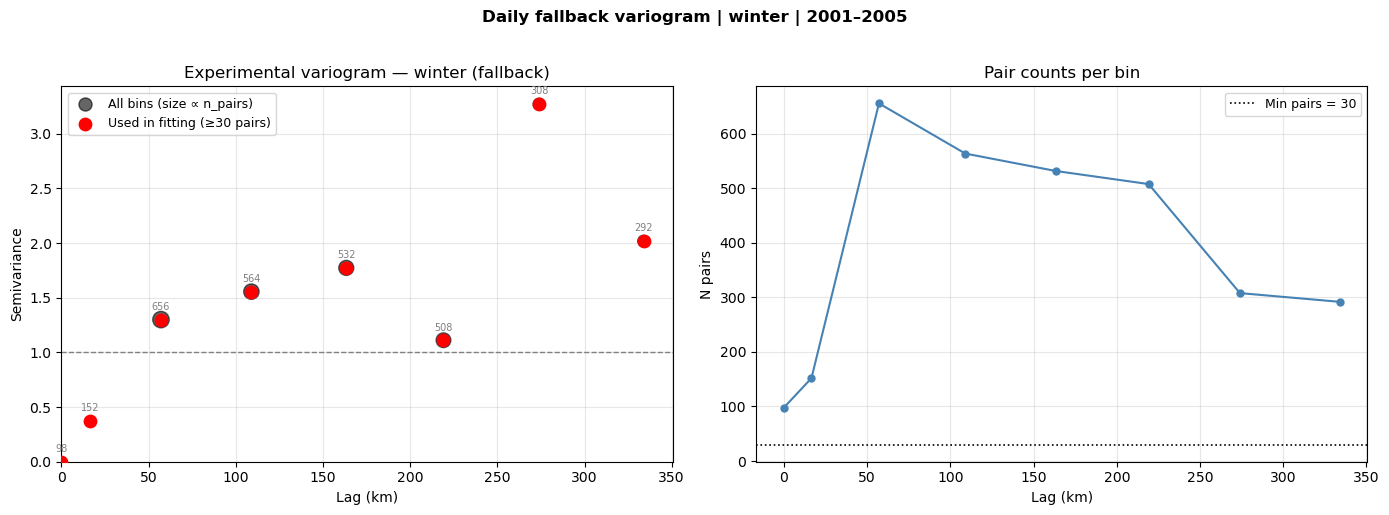

  exponential  nug=0.000  cc=1.000  range=75.3km  R²=1.000  ✓
  gaussian     nug=0.000  cc=1.000  range=71.7km  R²=1.000  ✓
  spherical    nug=0.000  cc=1.000  range=58.5km  R²=1.000  ✓


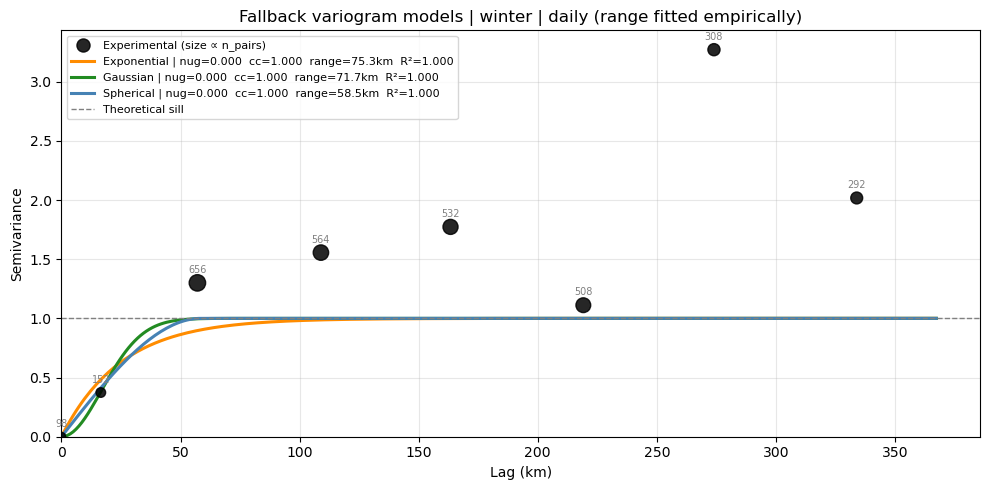


  ✓ Best model: GAUSSIAN  range=71.7km  R²=1.000)
  Saved → ..\Data\Processed\Bias_correction_daily\Insitu_kriged_daily\Variogram_analysis\fallback_variogram_params_daily.csv

════════════════════════════════════════════════════════════
  Fallback calibration — pre_monsoon
════════════════════════════════════════════════════════════


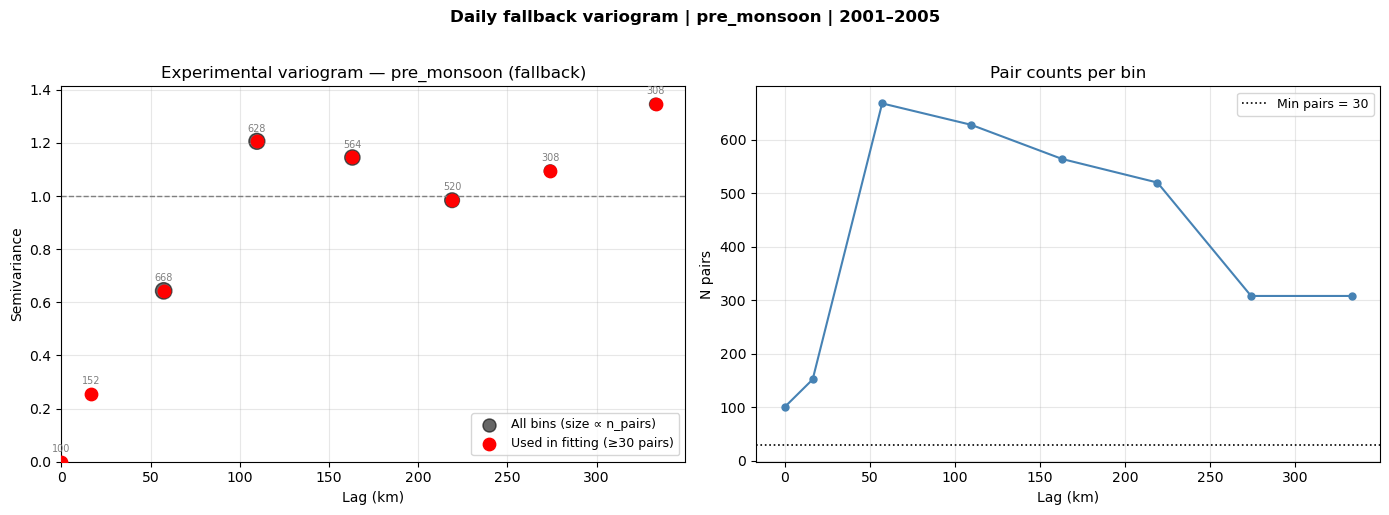

  exponential  nug=0.000  cc=0.973  range=146.8km  R²=1.000  ✓
  gaussian     nug=0.000  cc=0.998  range=137.1km  R²=1.000  ✓
  spherical    nug=0.000  cc=1.000  range=113.6km  R²=1.000  ✓


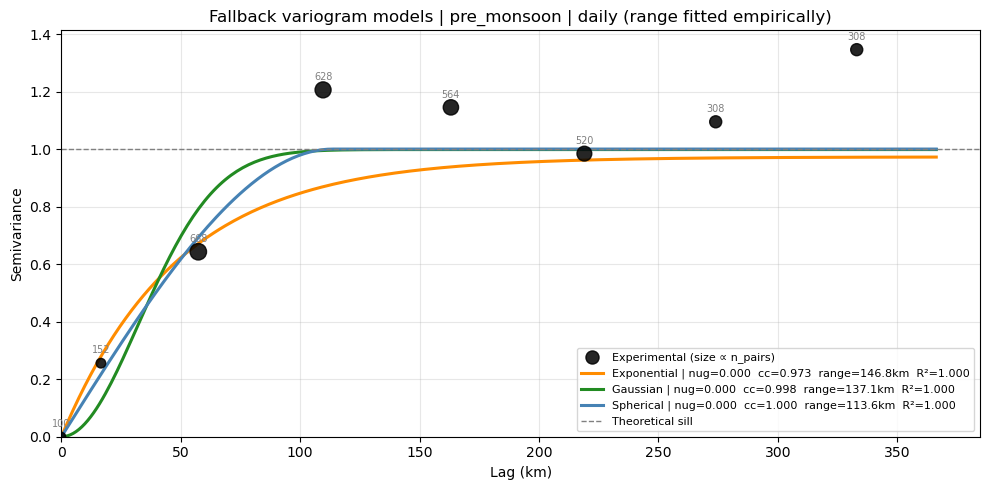


  ✓ Best model: EXPONENTIAL  range=146.8km  R²=1.000)
  Saved → ..\Data\Processed\Bias_correction_daily\Insitu_kriged_daily\Variogram_analysis\fallback_variogram_params_daily.csv

════════════════════════════════════════════════════════════
  Fallback calibration — monsoon
════════════════════════════════════════════════════════════


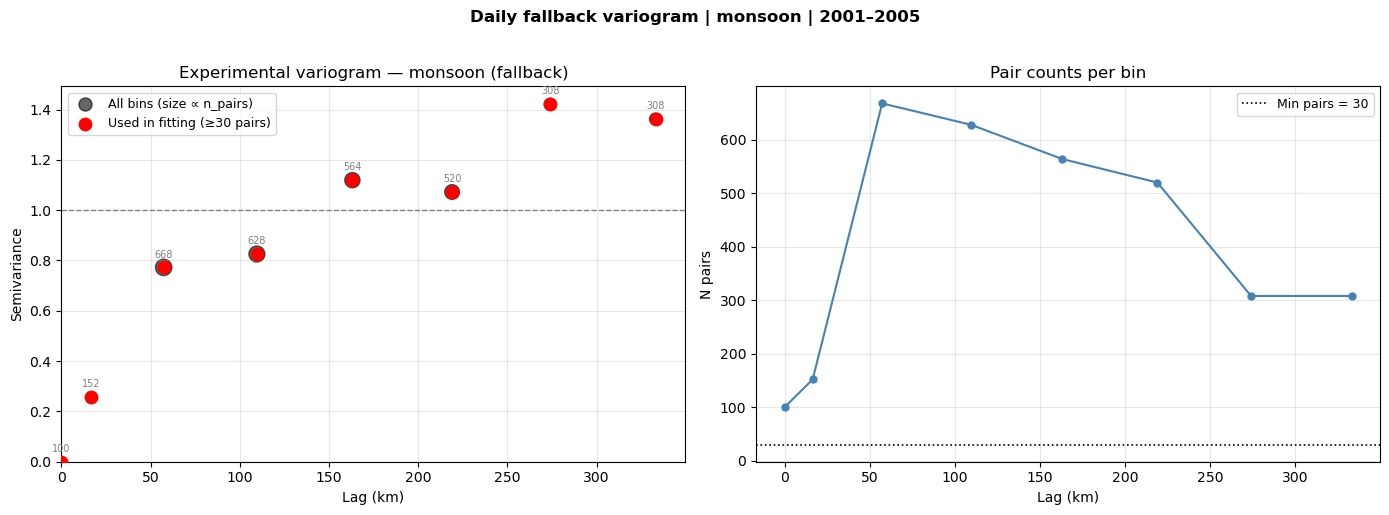

  exponential  nug=0.000  cc=1.000  range=143.0km  R²=1.000  ✓
  gaussian     nug=0.000  cc=0.844  range=83.3km  R²=1.000  ✓
  spherical    nug=0.000  cc=0.964  range=93.3km  R²=1.000  ✓


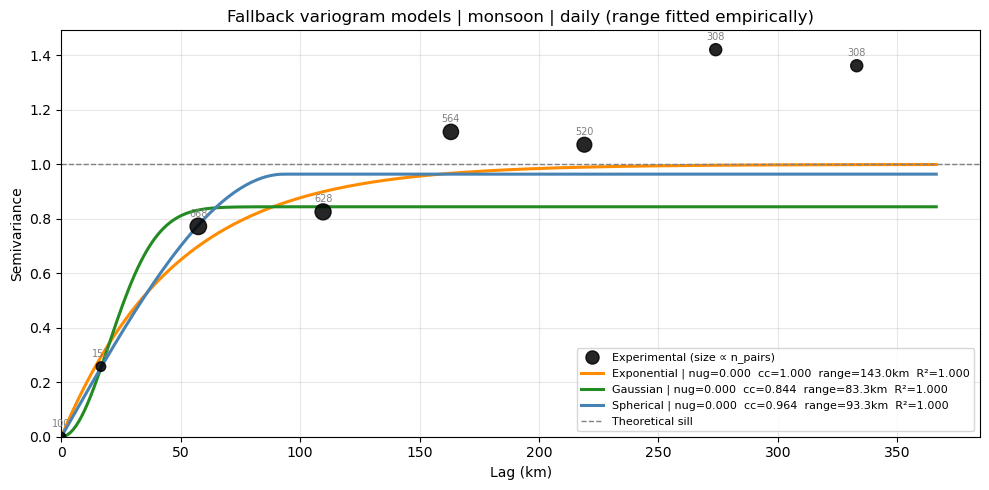


  ✓ Best model: EXPONENTIAL  range=143.0km  R²=1.000)
  Saved → ..\Data\Processed\Bias_correction_daily\Insitu_kriged_daily\Variogram_analysis\fallback_variogram_params_daily.csv

════════════════════════════════════════════════════════════
  Fallback calibration — post_monsoon
════════════════════════════════════════════════════════════


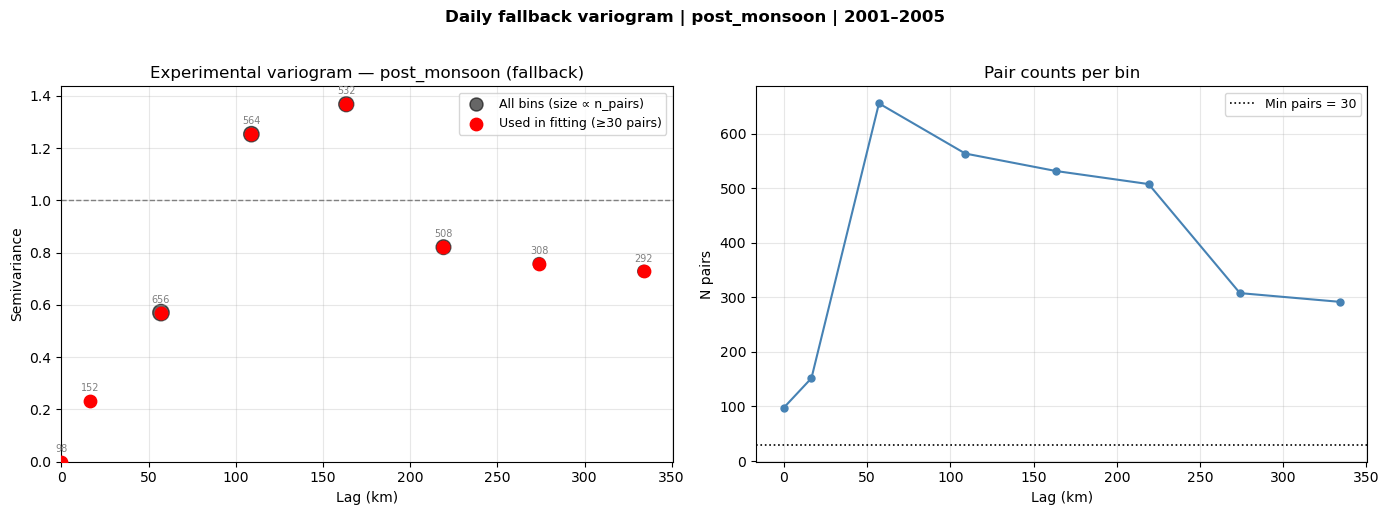

  exponential  nug=0.000  cc=1.000  range=171.6km  R²=1.000  ✓
  gaussian     nug=0.000  cc=1.000  range=129.7km  R²=1.000  ✓
  spherical    nug=0.000  cc=1.000  range=124.1km  R²=1.000  ✓


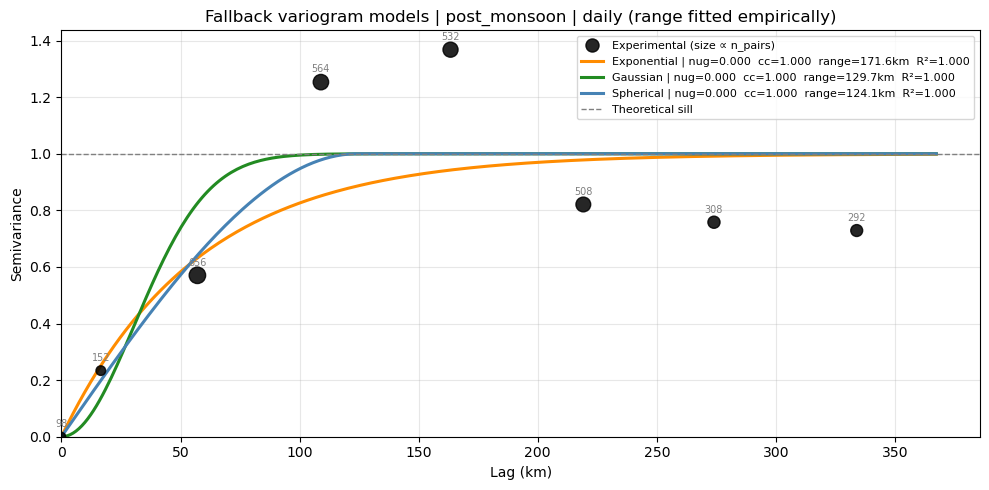


  ✓ Best model: GAUSSIAN  range=129.7km  R²=1.000)
  Saved → ..\Data\Processed\Bias_correction_daily\Insitu_kriged_daily\Variogram_analysis\fallback_variogram_params_daily.csv

════════════════════════════════════════════════════════════
  Fallback calibration complete → ..\Data\Processed\Bias_correction_daily\Insitu_kriged_daily\Variogram_analysis\fallback_variogram_params_daily.csv
════════════════════════════════════════════════════════════


In [28]:
# %%
# ── Section 6: Seasonal Fallback Variogram Calibration ────────────────────────
#
# Builds one fallback variogram per season from wet-day station means over
# the calibration period.  Range is fixed at FIXED_RANGE_KM; only nugget
# and partial_sill are fitted.  Used on days where per-day fitting fails.

# ── 6a: Wet-day means per station per season (calibration period) ─────────────

calib_data = insitu_train_daily[
    (insitu_train_daily['year'] >= CALIB_START_YEAR) &
    (insitu_train_daily['year'] <= CALIB_END_YEAR)
].copy()
calib_data['season'] = calib_data['month'].map(get_season)

wet_day_means = (
    calib_data[calib_data['insitu_prec'] >= WET_STATION_THRESHOLD]
    .groupby(['index_no', 'x', 'y', 'season'])
    .agg(
        wet_day_mean  = ('insitu_prec', 'mean'),
        wet_day_count = ('insitu_prec', 'count')
    )
    .reset_index()
)

# Require a minimum number of wet days for a stable mean
wet_day_means = wet_day_means[
    wet_day_means['wet_day_count'] >= MIN_WET_DAYS_FALLBACK
].copy()

print(f"\nWet-day means for fallback calibration "
      f"({CALIB_START_YEAR}–{CALIB_END_YEAR}):")
for s in SEASONS:
    n = (wet_day_means['season'] == s).sum()
    print(f"  {s}: {n} stations")

# ── 6b: Fit fallback variogram per season ────────────────────────────────────

for season in SEASONS:
    print(f"\n{'═'*60}")
    print(f"  Fallback calibration — {season}")
    print(f"{'═'*60}")

    df_s = (
        wet_day_means[wet_day_means['season'] == season]
        .copy()
        .reset_index(drop=True)
    )

    if len(df_s) < MIN_WET_STATIONS_ABS:
        print(f"  ⚠ Only {len(df_s)} stations — skipping")
        continue

    # Project to UTM km; shift x to avoid negative coords in gamv
    x_m_true, y_m = proj_utm(df_s['x'].values, df_s['y'].values)
    x_off = (
        int(np.ceil(-x_m_true.min() / 1000)) * 1000
        if x_m_true.min() < 0 else 0
    )
    df_s['x_km'] = (x_m_true + x_off) / 1000.0
    df_s['y_km'] = y_m / 1000.0

    # NSCORE transform on wet-day means
    try:
        ns_data, t_values, t_nscore = geostats.nscore(
            pd.DataFrame({'val': df_s['wet_day_mean'].values}), 'val'
        )
    except Exception as e:
        print(f"  ⚠ NSCORE failed ({e}) — skipping")
        continue

    df_s['ns'] = ns_data
    lookup_path = os.path.join(
        VAR_DIR, f"nscore_lookup_{season}_daily_fallback.csv"
    )
    pd.DataFrame(
        {'original_value': t_values, 'nscore_value': t_nscore}
    ).to_csv(lookup_path, index=False)

    # Omnidirectional experimental variogram
    cluster_extent = pdist(df_s[['x_km', 'y_km']].values).max()
    lag_cap        = cluster_extent / 2.0

    lag_exp, gamma_exp, n_pairs = geostats.gamv(
        df_s, 'x_km', 'y_km', 'ns',
        TMIN, TMAX,
        LAG_DIST, LAG_TOL, N_LAG,
        0, 90, BANDWH, isill=0
    )

    valid_bins = (
        (n_pairs >= MIN_PAIRS) &
        (lag_exp <= lag_cap) &
        np.isfinite(gamma_exp)
    )
    lag_fit    = lag_exp[valid_bins]
    gamma_fit  = gamma_exp[valid_bins]
    npairs_fit = n_pairs[valid_bins]

    if len(lag_fit) < 3:
        print(f"  ⚠ Only {len(lag_fit)} valid bins — skipping")
        continue

    # ── Diagnostic plot ───────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    valid_all      = np.isfinite(gamma_exp) & (n_pairs > 0)
    scatter_sizes  = (n_pairs / max(n_pairs.max(), 1)) * 120 + 20

    axes[0].scatter(lag_exp[valid_all], gamma_exp[valid_all],
                    s=scatter_sizes[valid_all], color='black', alpha=0.6,
                    label='All bins (size ∝ n_pairs)')
    axes[0].scatter(lag_fit, gamma_fit, s=80, color='red', zorder=5,
                    label=f'Used in fitting (≥{MIN_PAIRS} pairs)')
    for h, g, n in zip(lag_fit, gamma_fit, npairs_fit):
        axes[0].annotate(str(int(n)), (h, g),
                         textcoords='offset points', xytext=(0, 7),
                         ha='center', fontsize=7, color='gray')
    axes[0].axhline(1.0, color='gray', linestyle='--', linewidth=1)
    axes[0].set(xlabel='Lag (km)', ylabel='Semivariance',
                title=f'Experimental variogram — {season} (fallback)')
    axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)
    axes[0].set_xlim(left=0); axes[0].set_ylim(bottom=0)

    axes[1].plot(lag_exp[valid_all], n_pairs[valid_all], 'o-',
                 color='steelblue', linewidth=1.5, markersize=5)
    axes[1].axhline(MIN_PAIRS, color='black', linestyle=':', linewidth=1.2,
                    label=f'Min pairs = {MIN_PAIRS}')
    axes[1].set(xlabel='Lag (km)', ylabel='N pairs',
                title='Pair counts per bin')
    axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)

    plt.suptitle(
        f'Daily fallback variogram | {season} | {CALIB_START_YEAR}–{CALIB_END_YEAR}',
        fontweight='bold', y=1.02
    )
    plt.tight_layout(); plt.show()

    # ── Fit all three models — full 3-parameter iterative WLS ────────────
    # Range is FREE here so that each season produces its own empirically
    # justified correlation length.  This seasonal range is then used as
    # the fixed range in the per-day fitting in Section 8.
    range_init = float(
        lag_fit[np.argmax(gamma_fit >= SILL_TARGET)]
        if (gamma_fit >= SILL_TARGET).any()
        else lag_fit.mean()
    )
    p0     = [0.05, 0.90, range_init]
    bounds = ([0, 0, LAG_DIST], [1.0, 1.0, 2 * cluster_extent])

    fit_results = {}
    for model_name in MODEL_TRIAL_ORDER:
        try:
            popt, sigma_final, converged, _ = iterative_wls(
                MODEL_FUNCTIONS[model_name],
                lag_fit, gamma_fit, npairs_fit,
                p0, bounds, len(lag_fit)
            )
            nugget, partial_sill, range_km = (
                float(popt[0]), float(popt[1]), float(popt[2])
            )
            gamma_model = MODEL_FUNCTIONS[model_name](lag_fit, *popt)
            ss_res = np.sum(((gamma_fit - gamma_model) / sigma_final)**2)
            ss_tot = np.sum(((gamma_fit - gamma_fit.mean()) / sigma_final)**2)
            wls_r2 = float(1 - ss_res / ss_tot) if ss_tot > 1e-12 else np.nan

            sill_flag  = abs(nugget + partial_sill - 1.0) > 0.3
            range_flag = range_km < LAG_DIST or range_km > domain_extent
            fit_results[model_name] = {
                'nugget':       nugget,
                'partial_sill': partial_sill,
                'range_km':     range_km,
                'wls_r2':       wls_r2,
                'sill_flag':    sill_flag,
                'range_flag':   range_flag,
            }
            flags = ' '.join([
                '⚠ SILL'  if sill_flag  else '',
                '⚠ RANGE' if range_flag else '',
                '✓'       if not (sill_flag or range_flag) else '',
            ]).strip()
            print(f"  {model_name:<12} nug={nugget:.3f}  cc={partial_sill:.3f}  "
                  f"range={range_km:.1f}km  R²={wls_r2:.3f}  {flags}")
        except RuntimeError as e:
            print(f"  {model_name:<12} FAILED — {e}")

    if not fit_results:
        print(f"  ⚠ All models failed — skipping season")
        continue

    # ── Visual comparison ─────────────────────────────────────────────────
    h_plot = np.linspace(0, lag_fit.max() * 1.1, 300)
    fig, ax = plt.subplots(figsize=(10, 5))

    ss2 = (npairs_fit / npairs_fit.max()) * 120 + 20
    ax.scatter(lag_fit, gamma_fit, s=ss2, color='black', zorder=5,
               label='Experimental (size ∝ n_pairs)', alpha=0.85)
    for h, g, n in zip(lag_fit, gamma_fit, npairs_fit):
        ax.annotate(str(int(n)), (h, g),
                    textcoords='offset points', xytext=(0, 7),
                    ha='center', fontsize=7, color='gray')

    for model_name, res in fit_results.items():
        gamma_curve = MODEL_FUNCTIONS[model_name](
            h_plot, res['nugget'], res['partial_sill'], res['range_km']
        )
        ax.plot(h_plot, gamma_curve, color=COLORS[model_name], linewidth=2.2,
                label=(f"{model_name.capitalize()} | "
                       f"nug={res['nugget']:.3f}  cc={res['partial_sill']:.3f}  "
                       f"range={res['range_km']:.1f}km  R²={res['wls_r2']:.3f}"))

    ax.axhline(1.0, color='gray', linestyle='--', linewidth=1,
               label='Theoretical sill')
    ax.set(xlabel='Lag (km)', ylabel='Semivariance',
           title=(f'Fallback variogram models | {season} | daily '
                  f'(range fitted empirically)'))
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    ax.set_xlim(left=0); ax.set_ylim(bottom=0)
    plt.tight_layout(); plt.show()

    # ── Select best model ─────────────────────────────────────────────────
    # Prefer models passing both sill and range checks; relax progressively.
    qualified = {
        m: r for m, r in fit_results.items()
        if not r['sill_flag'] and not r['range_flag']
    }
    if not qualified:
        qualified = {m: r for m, r in fit_results.items() if not r['range_flag']}
    if not qualified:
        qualified = fit_results
    best_model = max(qualified, key=lambda m: qualified[m]['wls_r2'])
    best       = fit_results[best_model]
    print(f"\n  ✓ Best model: {best_model.upper()}  "
          f"range={best['range_km']:.1f}km  R²={best['wls_r2']:.3f})")

    # ── Save ──────────────────────────────────────────────────────────────
    row = {
        'season':             season,
        'n_stations':         len(df_s),
        'calib_start':        CALIB_START_YEAR,
        'calib_end':          CALIB_END_YEAR,
        'model_type':         best_model,
        'nugget':             round(best['nugget'],       6),
        'partial_sill':       round(best['partial_sill'], 6),
        'range_km':           round(best['range_km'],     3),   # empirically derived
        'wls_r2':             round(best['wls_r2'],       6),
        'nscore_lookup_path': lookup_path,
    }
    header = not os.path.exists(FALLBACK_PARAMS_CSV)
    pd.DataFrame([row]).to_csv(
        FALLBACK_PARAMS_CSV, mode='a', header=header, index=False
    )
    print(f"  Saved → {FALLBACK_PARAMS_CSV}")

print(f"\n{'═'*60}")
print(f"  Fallback calibration complete → {FALLBACK_PARAMS_CSV}")
print(f"{'═'*60}")

In [29]:

# %%
# ── Section 7: Grid Setup ─────────────────────────────────────────────────────
# Identical to the monthly code — derives UTM grid and WGS84 output profile
# from the template raster.

with rasterio.open(TEMPLATE_WGS84) as tmp:
    dst_crs = 'EPSG:32645'
    transform_utm, width_utm, height_utm = calculate_default_transform(
        tmp.crs, dst_crs, tmp.width, tmp.height, *tmp.bounds
    )
    out_profile_wgs84 = tmp.profile.copy()

# 1D coordinate vectors for PyKrige (in metres, grid_y south→north)
grid_x = np.linspace(
    transform_utm[2],
    transform_utm[2] + (width_utm  * transform_utm[0]),
    width_utm
)
grid_y = np.linspace(
    transform_utm[5] + (height_utm * transform_utm[4]),
    transform_utm[5],
    height_utm
)


# %%
# ── Section 8: Daily Kriging Loop ─────────────────────────────────────────────

fallback_params = pd.read_csv(FALLBACK_PARAMS_CSV).set_index('season')

# Build per-season fixed-range variogram wrappers.
# The range for each season comes from the empirical iterative WLS fit in
# Section 6.  If a season is missing from fallback_params (calibration
# failed), fall back to FIXED_RANGE_FALLBACK_KM.
seasonal_range_km    = {}
seasonal_fixed_funcs = {}
for season in SEASONS:
    if season in fallback_params.index:
        rng = float(fallback_params.loc[season, 'range_km'])
    else:
        rng = FIXED_RANGE_FALLBACK_KM
        print(f"  ⚠ No fallback params for {season} — "
              f"using default range {FIXED_RANGE_FALLBACK_KM} km")
    seasonal_range_km[season]    = rng
    seasonal_fixed_funcs[season] = make_fixed_range_funcs(rng)

print("\n  Seasonal ranges loaded for per-day fitting:")
for s, rng in seasonal_range_km.items():
    src = "empirical" if s in fallback_params.index else "default"
    print(f"    {s:<16} {rng:.1f} km  ({src})")

target_dates  = pd.date_range(start=KRIG_START_DAY, end=KRIG_END_DAY, freq='D')
utm_temp_path = os.path.join(TEMP_DIR, "temp_utm.tif")
log_rows      = []

utm_meta = {
    'driver': 'GTiff', 'height': height_utm, 'width': width_utm,
    'count': 1, 'dtype': 'float32', 'crs': dst_crs,
    'transform': transform_utm, 'nodata': NODATA_OUT,
}

for date in target_dates:
    date_str = date.strftime('%Y%m%d')
    season   = get_season(date.month)

    # ── Extract today's data ───────────────────────────────────────────────
    df_d = insitu_train_daily[
        (insitu_train_daily['year']  == date.year)  &
        (insitu_train_daily['month'] == date.month) &
        (insitu_train_daily['day']   == date.day)
    ].copy()

    n_available = len(df_d)
    df_wet      = df_d[df_d['insitu_prec'] >= WET_STATION_THRESHOLD].copy()
    n_wet       = len(df_wet)
    wet_frac    = n_wet / n_available if n_available > 0 else 0.0

    method_used      = None
    model_used       = ''
    nugget_log       = np.nan
    partial_sill_log = np.nan

    # Seasonal range and fixed-range variogram wrappers for this day
    season_range_km   = seasonal_range_km.get(season,    FIXED_RANGE_FALLBACK_KM)
    fixed_funcs_today = seasonal_fixed_funcs.get(season, make_fixed_range_funcs(FIXED_RANGE_FALLBACK_KM))

    # ──────────────────────────────────────────────────────────────────────
    # BRANCH A: insufficient wet stations → bilinear + Gaussian fallback
    # ──────────────────────────────────────────────────────────────────────
    if n_wet < MIN_WET_STATIONS_ABS or wet_frac < MIN_WET_STATIONS_PCT:
        rain_grid = (
            bilinear_gaussian_fallback(df_d, grid_x, grid_y, GAUSSIAN_SMOOTH_SIGMA)
            if n_available > 0
            else np.zeros((height_utm, width_utm), dtype='float32')
        )
        method_used = 'bilinear_gaussian'

    # ──────────────────────────────────────────────────────────────────────
    # BRANCH B: sufficient wet stations → attempt kriging
    # ──────────────────────────────────────────────────────────────────────
    else:
        # ── B1: NSCORE transform on wet-station values ────────────────────
        try:
            ns_data, t_vals, t_ns = geostats.nscore(
                pd.DataFrame({'val': df_wet['insitu_prec'].values}), 'val'
            )
            df_wet['ns'] = ns_data
            lookup_df    = pd.DataFrame({
                'original_value': t_vals,
                'nscore_value':   t_ns,
            })
            nscore_ok = True
        except Exception:
            nscore_ok = False

        if not nscore_ok:
            rain_grid   = bilinear_gaussian_fallback(
                df_d, grid_x, grid_y, GAUSSIAN_SMOOTH_SIGMA
            )
            method_used = 'bilinear_gaussian_nscore_fail'

        else:
            # ── B2: UTM coordinates for wet stations ──────────────────────
            x_m_wet, y_m_wet = proj_utm(df_wet['x'].values, df_wet['y'].values)
            x_off    = (
                int(np.ceil(-x_m_wet.min() / 1000)) * 1000
                if x_m_wet.min() < 0 else 0
            )
            x_km_wet = (x_m_wet + x_off) / 1000.0
            y_km_wet = y_m_wet / 1000.0

            # ── B3: Per-day experimental variogram ────────────────────────
            gamv_ok = False
            try:
                lag_exp, gamma_exp, n_pairs = geostats.gamv(
                    df_wet.assign(x_km=x_km_wet, y_km=y_km_wet),
                    'x_km', 'y_km', 'ns',
                    TMIN, TMAX,
                    LAG_DIST, LAG_TOL, N_LAG,
                    0, 90, BANDWH, isill=0
                )
                lag_cap    = pdist(np.column_stack([x_km_wet, y_km_wet])).max() / 2.0
                valid_bins = (
                    (n_pairs >= MIN_PAIRS) &
                    (lag_exp <= lag_cap) &
                    np.isfinite(gamma_exp)
                )
                lag_fit    = lag_exp[valid_bins]
                gamma_fit  = gamma_exp[valid_bins]
                npairs_fit = n_pairs[valid_bins]
                gamv_ok    = len(lag_fit) >= 3
            except Exception:
                gamv_ok = False

            # ── B4: Per-day fixed-range variogram fit ─────────────────────
            # Try models in order; accept first non-degenerate fit.
            nugget_use = partial_sill_use = model_use = None

            if gamv_ok:
                for model_name in MODEL_TRIAL_ORDER:
                    try:
                        nugget, partial_sill, wls_r2 = fit_fixed_range_wls(
                            fixed_funcs_today, model_name,
                            lag_fit, gamma_fit, npairs_fit
                        )
                        # Reject degenerate fits: sill must be positive and
                        # R² must be non-negative (better than flat line)
                        if wls_r2 >= 0.0 and partial_sill > 0:
                            nugget_use       = nugget
                            partial_sill_use = partial_sill
                            model_use        = model_name
                            method_used      = 'kriging_per_day'
                            break
                    except RuntimeError:
                        continue

            # ── B5: Fall back to seasonal params if per-day fit failed ────
            if model_use is None:
                if season in fallback_params.index:
                    fp               = fallback_params.loc[season]
                    nugget_use       = float(fp['nugget'])
                    partial_sill_use = float(fp['partial_sill'])
                    model_use        = fp['model_type']
                    method_used      = 'kriging_seasonal_fallback'
                else:
                    # No seasonal fallback available — bilinear
                    rain_grid   = bilinear_gaussian_fallback(
                        df_d, grid_x, grid_y, GAUSSIAN_SMOOTH_SIGMA
                    )
                    method_used = 'bilinear_gaussian_no_fallback'

            # ── B6: Ordinary kriging ──────────────────────────────────────
            if model_use is not None:
                ok_model = OrdinaryKriging(
                    x_m_wet, y_m_wet, df_wet['ns'].values,
                    variogram_model=model_use,
                    variogram_parameters={
                        'sill':   partial_sill_use,   # PyKrige 'sill' = partial sill
                        'range':  season_range_km * 1000.0,   # km → m
                        'nugget': nugget_use,
                    },
                    verbose=False,
                    enable_plotting=False,
                )
                kmap, _ = ok_model.execute(
                    'grid', grid_x, grid_y, backend='vectorized'
                )

                # Flip to rasterio top-down convention
                kmap_flipped = np.flipud(kmap.data)

                # Back-transform NSCORE → rainfall.
                # Kriged values below the wet-station NSCORE range extrapolate
                # to the minimum wet-station rainfall; the final clip to zero
                # removes any remaining negative artefacts.
                rain_grid = safe_nscore_lookup(
                    kmap_flipped.flatten(), lookup_df
                ).reshape(kmap_flipped.shape)
                rain_grid = np.clip(rain_grid, 0, None).astype('float32')

                nugget_log       = nugget_use
                partial_sill_log = partial_sill_use
                model_used       = model_use

    # ── Save GeoTIFF ──────────────────────────────────────────────────────
    with rasterio.open(utm_temp_path, 'w', **utm_meta) as dst:
        dst.write(rain_grid, 1)

    final_path = os.path.join(OUTPUT_DIR, f"insitu_precip_{date_str}.tif")
    with rasterio.open(utm_temp_path) as src:
        with rasterio.open(final_path, 'w', **out_profile_wgs84) as dst:
            reproject(
                source      = rasterio.band(src, 1),
                destination = rasterio.band(dst, 1),
                src_transform = src.transform,
                src_crs       = src.crs,
                dst_transform = dst.transform,
                dst_crs       = dst.crs,
                resampling    = Resampling.bilinear,
            )

    # ── Log row ───────────────────────────────────────────────────────────
    log_rows.append({
        'date':         date_str,
        'season':       season,
        'n_available':  n_available,
        'n_wet':        n_wet,
        'wet_frac':     round(wet_frac, 4),
        'method':       method_used,
        'model':        model_used,
        'range_km':     round(season_range_km, 1),
        'nugget':       round(nugget_log,       4) if not np.isnan(nugget_log)       else '',
        'partial_sill': round(partial_sill_log, 4) if not np.isnan(partial_sill_log) else '',
    })

    # Progress — print on the first day of each month
    if date.day == 1:
        print(f"  {date_str}  n_wet={n_wet}/{n_available}  "
              f"wet%={wet_frac*100:.0f}%  method={method_used}")

# ── Save log and print summary ────────────────────────────────────────────────
log_df = pd.DataFrame(log_rows)
log_df.to_csv(LOG_CSV, index=False)

print(f"\n{'═'*60}")
print(f"  Daily kriging complete")
print(f"  Total days processed : {len(log_df)}")
print(f"\n  Method breakdown:")
for method, count in log_df['method'].value_counts().items():
    pct = count / len(log_df) * 100
    print(f"    {method:<40} {count:>5}  ({pct:.1f}%)")
print(f"\n  Log saved → {LOG_CSV}")
print(f"{'═'*60}")


  Seasonal ranges loaded for per-day fitting:
    winter           71.7 km  (empirical)
    pre_monsoon      146.8 km  (empirical)
    monsoon          143.0 km  (empirical)
    post_monsoon     129.7 km  (empirical)
  20010101  n_wet=21/49  wet%=43%  method=kriging_per_day
  20010201  n_wet=0/49  wet%=0%  method=bilinear_gaussian
  20010301  n_wet=1/49  wet%=2%  method=bilinear_gaussian
  20010401  n_wet=18/49  wet%=37%  method=bilinear_gaussian
  20010501  n_wet=24/49  wet%=49%  method=kriging_per_day
  20010601  n_wet=18/49  wet%=37%  method=bilinear_gaussian
  20010701  n_wet=34/49  wet%=69%  method=kriging_per_day
  20010801  n_wet=37/50  wet%=74%  method=kriging_per_day
  20010901  n_wet=35/49  wet%=71%  method=kriging_per_day
  20011001  n_wet=24/47  wet%=51%  method=kriging_per_day
  20011101  n_wet=7/48  wet%=15%  method=bilinear_gaussian
  20011201  n_wet=0/48  wet%=0%  method=bilinear_gaussian
  20020101  n_wet=0/50  wet%=0%  method=bilinear_gaussian
  20020201  n_wet=0/49 